In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_excel("ABC Company.xlsx")
df.head()

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,2023-02-06 00:00:00,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,2023-06-06 00:00:00,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,2023-05-06 00:00:00,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,2023-05-06 00:00:00,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,2023-10-06 00:00:00,231,NaN,5000000.0


In [4]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

(458, 9)
<class 'pandas.DataFrame'>
RangeIndex: 458 entries, 0 to 457
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      458 non-null    str    
 1   Team      458 non-null    str    
 2   Number    458 non-null    int64  
 3   Position  458 non-null    str    
 4   Age       458 non-null    int64  
 5   Height    458 non-null    object 
 6   Weight    458 non-null    int64  
 7   College   374 non-null    str    
 8   Salary    447 non-null    float64
dtypes: float64(1), int64(3), object(1), str(4)
memory usage: 49.4+ KB
None
Name         0
Team         0
Number       0
Position     0
Age          0
Height       0
Weight       0
College     84
Salary      11
dtype: int64


In [5]:
df['Height'] = np.random.randint(150,181,size=len(df))
print(df['Height'].dtype)
print(df['Height'].head())

int32
0    161
1    154
2    168
3    174
4    173
Name: Height, dtype: int32


In [6]:
#Team wise employee distribution
team_count = df['Team'].value_counts()
print(team_count)

Team
New Orleans Pelicans      19
Memphis Grizzlies         18
New York Knicks           16
Milwaukee Bucks           16
Utah Jazz                 16
Boston Celtics            15
Brooklyn Nets             15
Philadelphia 76ers        15
Toronto Raptors           15
Golden State Warriors     15
Los Angeles Clippers      15
Los Angeles Lakers        15
Phoenix Suns              15
Sacramento Kings          15
Chicago Bulls             15
Cleveland Cavaliers       15
Detroit Pistons           15
Indiana Pacers            15
Dallas Mavericks          15
Houston Rockets           15
San Antonio Spurs         15
Atlanta Hawks             15
Charlotte Hornets         15
Miami Heat                15
Washington Wizards        15
Denver Nuggets            15
Oklahoma City Thunder     15
Portland Trail Blazers    15
Orlando Magic             14
Minnesota Timberwolves    14
Name: count, dtype: int64


In [7]:
team_percentage = df['Team'].value_counts(normalize=True)*100
print(team_percentage.round(2))

Team
New Orleans Pelicans      4.15
Memphis Grizzlies         3.93
New York Knicks           3.49
Milwaukee Bucks           3.49
Utah Jazz                 3.49
Boston Celtics            3.28
Brooklyn Nets             3.28
Philadelphia 76ers        3.28
Toronto Raptors           3.28
Golden State Warriors     3.28
Los Angeles Clippers      3.28
Los Angeles Lakers        3.28
Phoenix Suns              3.28
Sacramento Kings          3.28
Chicago Bulls             3.28
Cleveland Cavaliers       3.28
Detroit Pistons           3.28
Indiana Pacers            3.28
Dallas Mavericks          3.28
Houston Rockets           3.28
San Antonio Spurs         3.28
Atlanta Hawks             3.28
Charlotte Hornets         3.28
Miami Heat                3.28
Washington Wizards        3.28
Denver Nuggets            3.28
Oklahoma City Thunder     3.28
Portland Trail Blazers    3.28
Orlando Magic             3.06
Minnesota Timberwolves    3.06
Name: proportion, dtype: float64


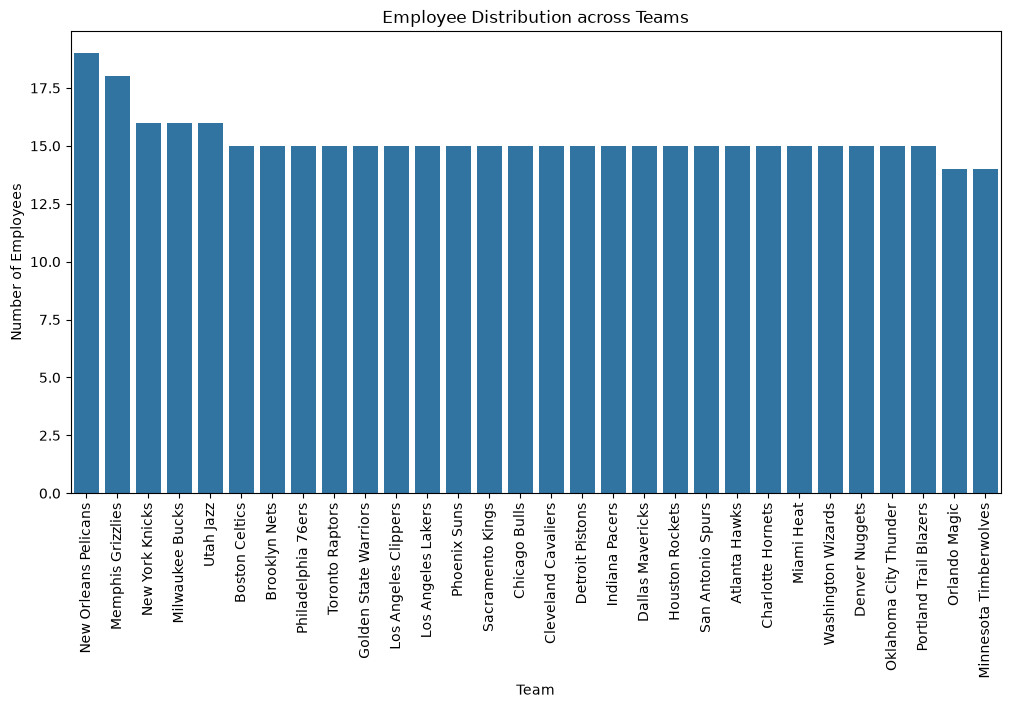

In [8]:
#Graph
plt.figure(figsize=(12,6))
sns.countplot(data=df, x='Team', order=df['Team'].value_counts().index)
plt.title('Employee Distribution across Teams')
plt.xlabel('Team')
plt.ylabel('Number of Employees')
plt.xticks(rotation=90)
plt.show()

In [9]:
#Position wise employee distribution
position_count = df['Position'].value_counts()
print(position_count)

Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64


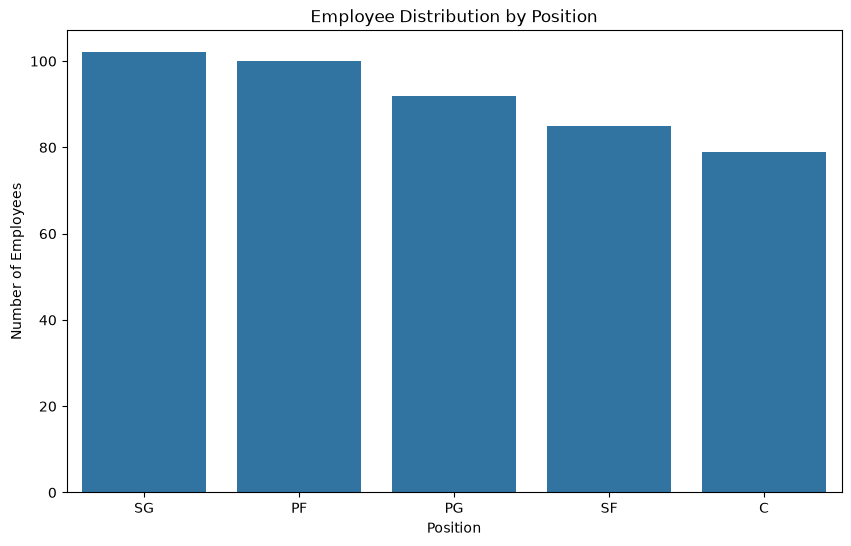

In [10]:
plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Position', order=df['Position'].value_counts().index)
plt.title('Employee Distribution by Position')
plt.xlabel('Position')
plt.ylabel('Number of Employees')
plt.show()

In [12]:
#Age Group Analysis
bins = [19,25,30,35,40,45]
labels = ['20-25','26-30','31-35','36-40','41-45']
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels)
age_group_count = df['Age_Group'].value_counts().sort_index()
print(age_group_count)

Age_Group
20-25    198
26-30    167
31-35     68
36-40     23
41-45      0
Name: count, dtype: int64


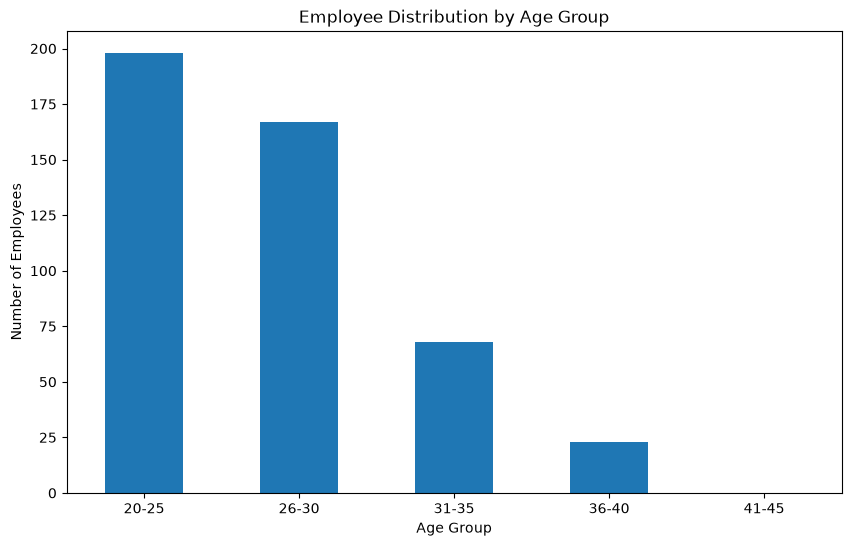

In [21]:
plt.figure(figsize=(10,6))
age_group_count.plot(kind='bar')
plt.title('Employee Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0)
plt.show()

In [15]:
print('Predominent Age Group: ', age_group_count.idxmax())
print('Number of Employees: ', age_group_count.max())

Predominent Age Group:  20-25
Number of Employees:  198


In [18]:
#salary expenditure
team_salary = df.groupby('Team')['Salary'].sum().sort_values(ascending=False)
print('Salary Expenditure by Team: ')
print(team_salary)
print('\nTeam with Highest Salary Expenditure: ')
print(team_salary.idxmax())
print('Highest Salary Expenditure: ')
print(team_salary.max())

Salary Expenditure by Team: 
Team
Cleveland Cavaliers       106988689.0
Los Angeles Clippers       94854640.0
Oklahoma City Thunder      93765298.0
Golden State Warriors      88868997.0
Chicago Bulls              86783378.0
San Antonio Spurs          84442733.0
New Orleans Pelicans       82750774.0
Miami Heat                 82515673.0
Charlotte Hornets          78340920.0
Memphis Grizzlies          76550880.0
Washington Wizards         76328636.0
Houston Rockets            75283021.0
New York Knicks            73303898.0
Atlanta Hawks              72902950.0
Los Angeles Lakers         71770431.0
Sacramento Kings           71683666.0
Dallas Mavericks           71198732.0
Toronto Raptors            71117611.0
Milwaukee Bucks            69603517.0
Detroit Pistons            67168263.0
Indiana Pacers             66751826.0
Utah Jazz                  64007367.0
Phoenix Suns               63445135.0
Orlando Magic              60161470.0
Denver Nuggets             60121930.0
Minnesota Timber

In [19]:
position_salary = df.groupby('Position')['Salary'].sum().sort_values(ascending=False)
print('Salary Expenditure by Position: ')
print(position_salary)
print('\nPosition with Highest Salary Expenditure: ')
print(position_salary.idxmax())
print('Highest Salary Expenditure: ')
print(position_salary.max())

Salary Expenditure by Position: 
Position
C     466377332.0
PG    446848971.0
PF    442560850.0
SF    408020976.0
SG    396976258.0
Name: Salary, dtype: float64

Position with Highest Salary Expenditure: 
C
Highest Salary Expenditure: 
466377332.0


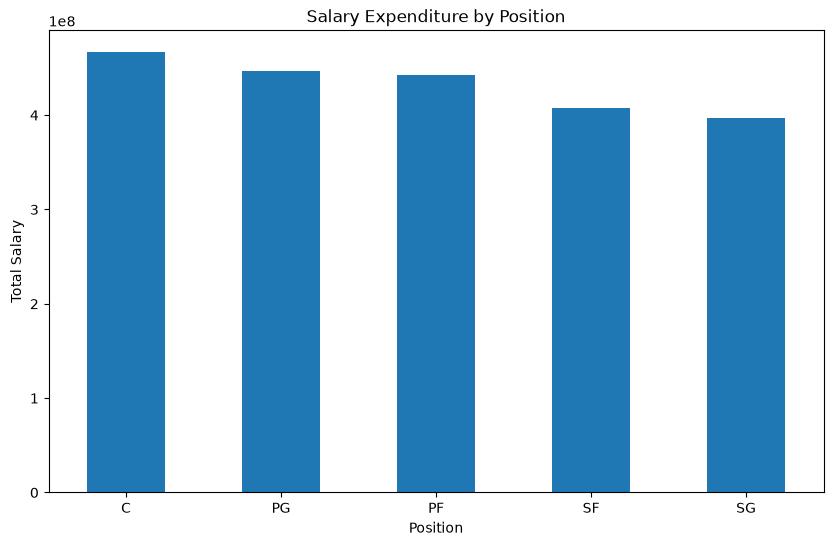

In [22]:
plt.figure(figsize=(10,6))
position_salary.plot(kind='bar')
plt.title('Salary Expenditure by Position')
plt.xlabel('Position')
plt.ylabel('Total Salary')
plt.xticks(rotation=0)
plt.show()

In [23]:
#Age vs Salary Correlation
correlation = df['Age'].corr(df['Salary'])
print('Correlation between Age and Salary: ', correlation)

Correlation between Age and Salary:  0.21400941226570974


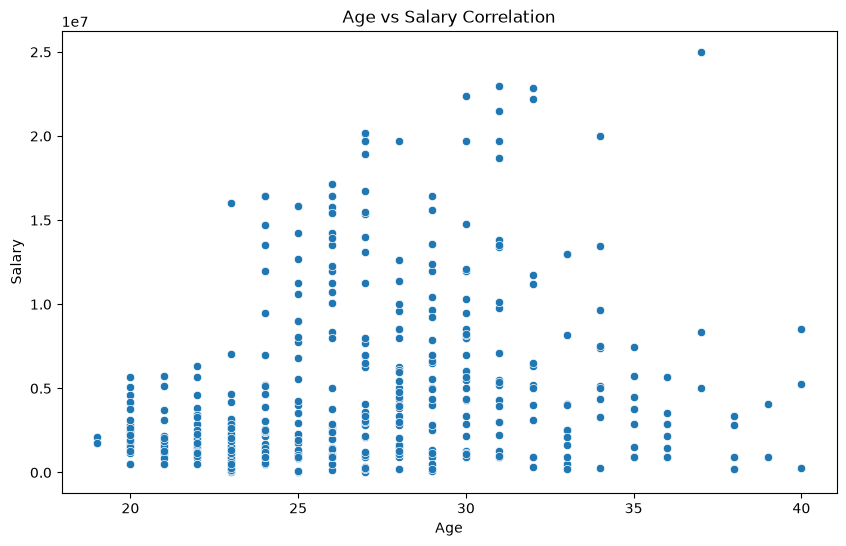

In [24]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Age', y='Salary')
plt.title('Age vs Salary Correlation')
plt.xlabel('Age')
plt.ylabel('Salary')
plt.show()

# Final Data Story

The analysis of the employee dataset revealed several important insights.

1. Team Analysis:
The New Orleans Pelicans has the highest number of employees, with 19 employees (4.15%).

2. Position Analysis:
The employees are distributed across different positions, including C, PG, PF, SF, and SG.

3. Age Group Analysis:
The predominant age group is 20–25 years, with 198 employees. This indicates that most employees in the dataset belong to the younger age group.

4. Salary Expenditure Analysis:
The Cleveland Cavaliers has the highest total salary expenditure, amounting to 106,988,689.

5. Age vs Salary Correlation:
The correlation coefficient between age and salary is approximately 0.21, indicating a weak positive relationship between age and salary.

#Overall Findings

The analysis shows that employees are distributed across multiple teams and positions. The 20–25 age group represents the largest share of employees, while the Cleveland Cavaliers has the highest total salary expenditure. The weak positive correlation suggests that age alone does not strongly explain salary differences.

These findings help us understand employee distribution, age patterns, and salary expenditure in the dataset.